In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 16

# Exercise 1

x1=-0.999996
%error=-0.00038147
f(x1)=-6.10351e-05

x2=4.33333
%error=0.000117375
f(x2)=-8.13801e-05


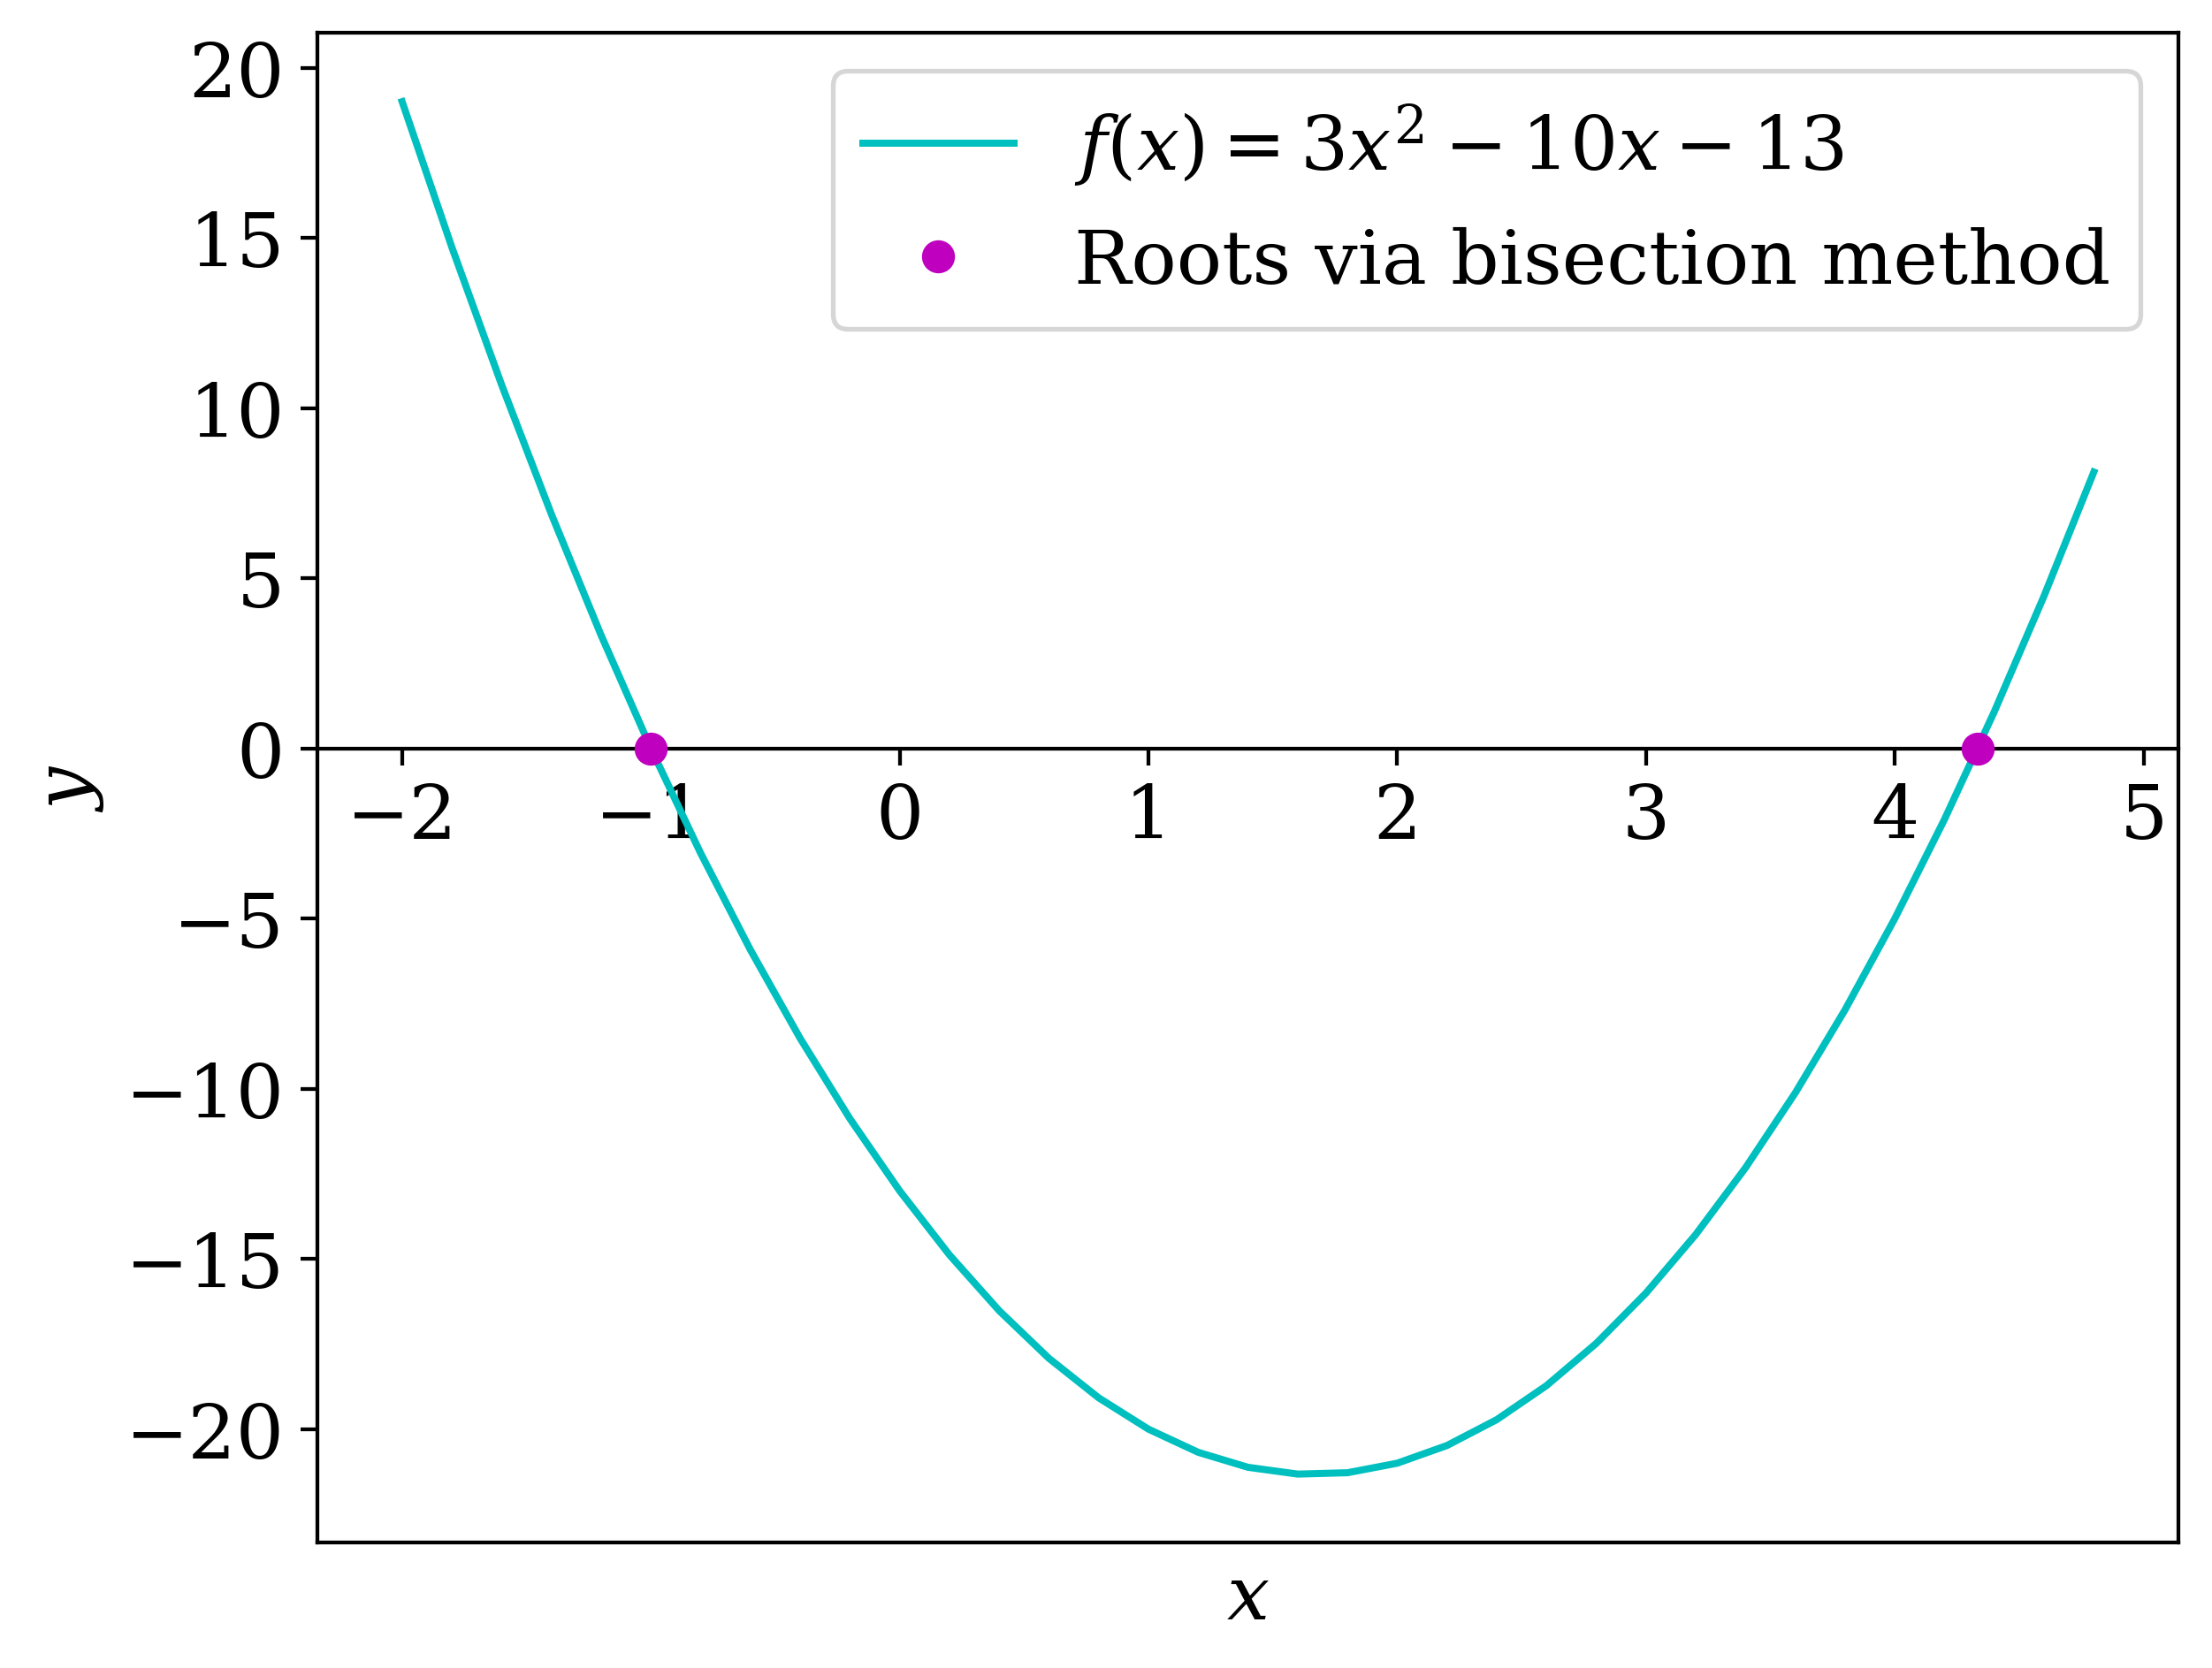

In [2]:
"""Definition of function:

f(x) = 3x^2 - 10x - 13
"""
def parabola(x):
  return 3 * x**2 - 10 * x - 13


"""Find root x of function where a<x<b via bisection method

Optionally return number of steps it took to find the root
"""
def root(a=-4, b=0, tol=0.0001, steps=False):
  try:
    if np.sign(parabola(a)) == np.sign(parabola(b)):
      raise ValueError

    x = 0.5 * (a + b)
    nsteps = 0

    while(abs(parabola(x))>tol):
      x = 0.5 * (a + b)
      nsteps += 1

      if np.sign(parabola(a)) == np.sign(parabola(x)):
        a = x
      else:
        b = x

    return nsteps if steps else x

  except ValueError:
    print("Choose a different value for x1 or x2")


# Actual roots of function f(x) = 3x^2 - 10x - 13
true_x1 = -1
true_x2 = 13/3

x = np.arange(-2.0, 5.0, 0.2)
y = parabola(x)

x1 = root(-3,0)
x2 = root(3,5)

y1 = parabola(x1)
y2 = parabola(x2)

print(f'x1={x1:.6}\n%error={abs(x1-true_x1)*100/true_x1:.6}\nf(x1)={y1:.6}\n')
print(f'x2={x2:.6}\n%error={abs(x2-true_x2)*100/true_x2:.6}\nf(x2)={y2:.6}')

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(x, y, label='$f(x) = 3x^2 - 10x - 13$', color='c')
ax.plot((x1, x2), (y1, y2), 'mo', label='Roots via bisection method')
ax.legend()
ax.set_xticks([])

plt.xlabel('$x$')
plt.ylabel('$y$')

ax.secondary_xaxis(0, transform=ax.transData)

plt.savefig('bisection_parabola.png', bbox_inches='tight')
plt.show()

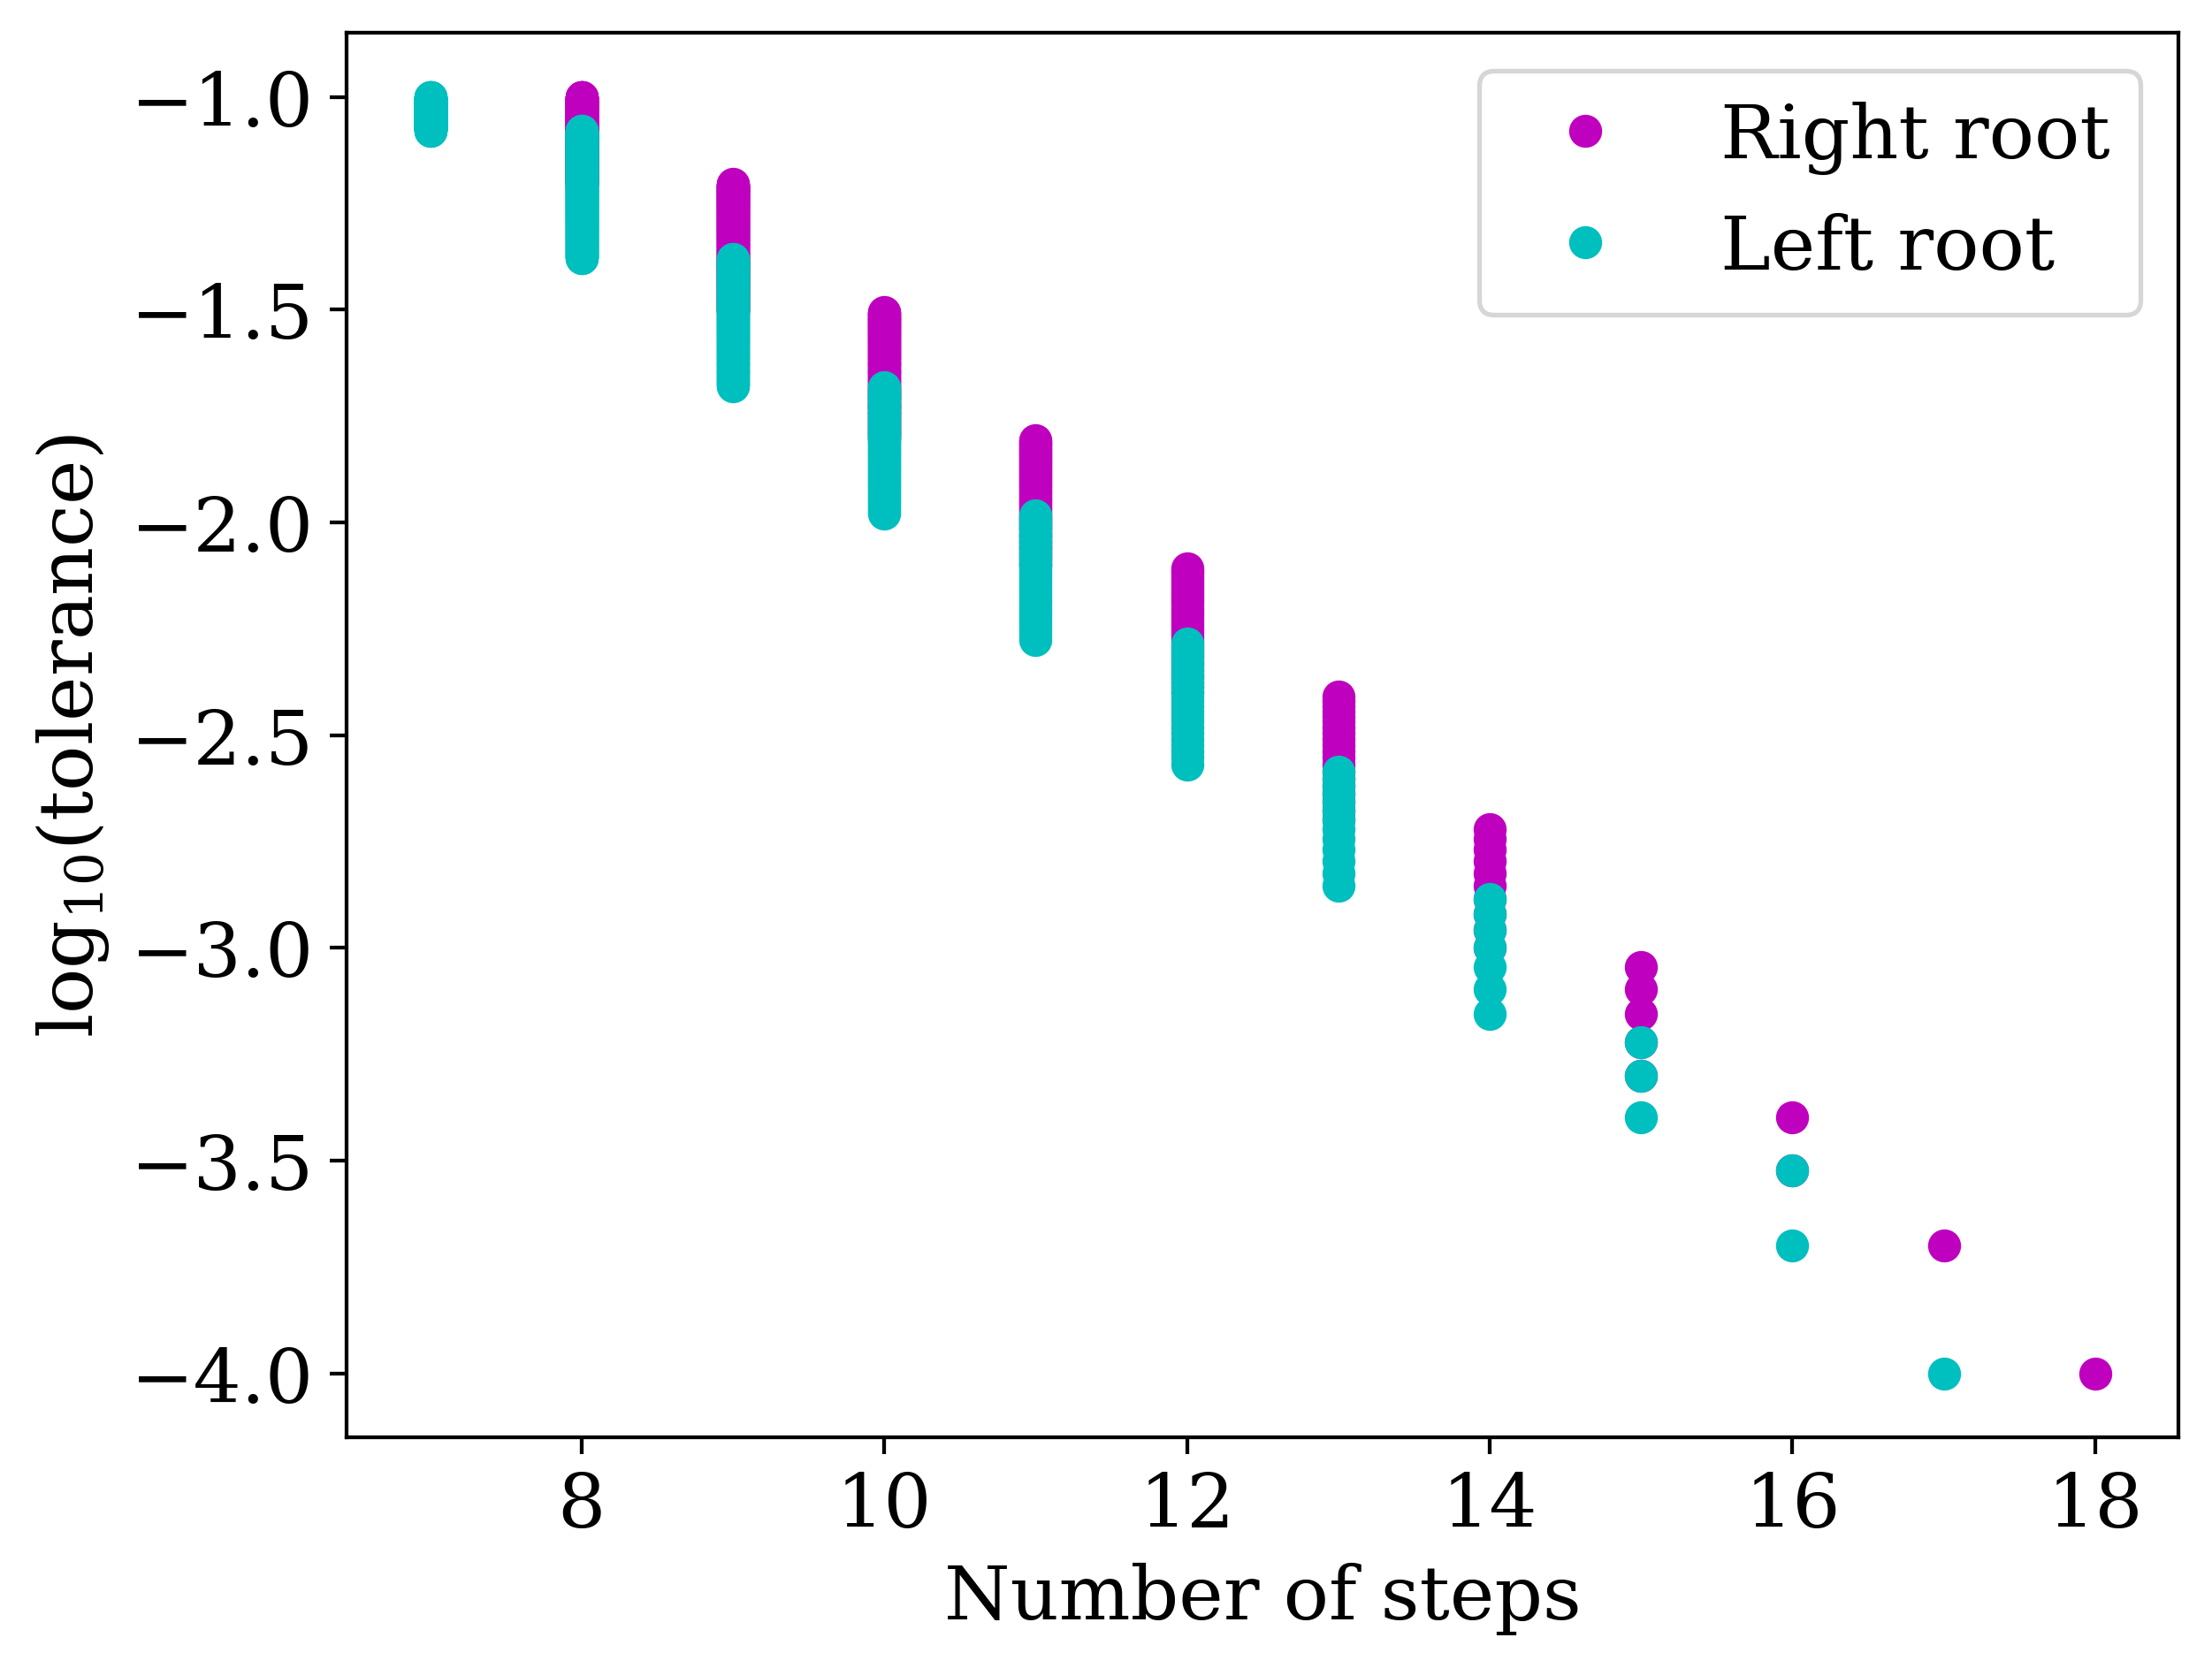

In [3]:
"""Get both roots via bisection method in specified intervals
"""
def find_roots(tol):

  nr = root(-3, 0, tol, True)
  nl = root(3, 5, tol, True)

  return nr, nl


tols = np.linspace(0.0001, 0.1, num=1000)

nsr, nsl = zip(*[find_roots(tol) for tol in tols])
tols_log10 = np.log10(tols)

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(nsr, tols_log10, 'mo', label='Right root')
ax.plot(nsl, tols_log10, 'co', label='Left root')
ax.legend()

plt.xlabel('Number of steps')
plt.ylabel('log$_{10}$(tolerance)')

plt.savefig('bisection_steps.png', bbox_inches='tight')
plt.show()

# Exercise 2

<>:34: SyntaxWarning: invalid escape sequence '\ '
<>:34: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_4832/4073476043.py:34: SyntaxWarning: invalid escape sequence '\ '
  ax.plot(x, parabola_prime(x), label='$f\ \'(x) = 6x-10$', color='y')


x1=-1.0
%error=-4.24462e-05
f(x1)=6.79139e-06

x2=4.33333
%error=2.85915e-06
f(x2)=1.98234e-06


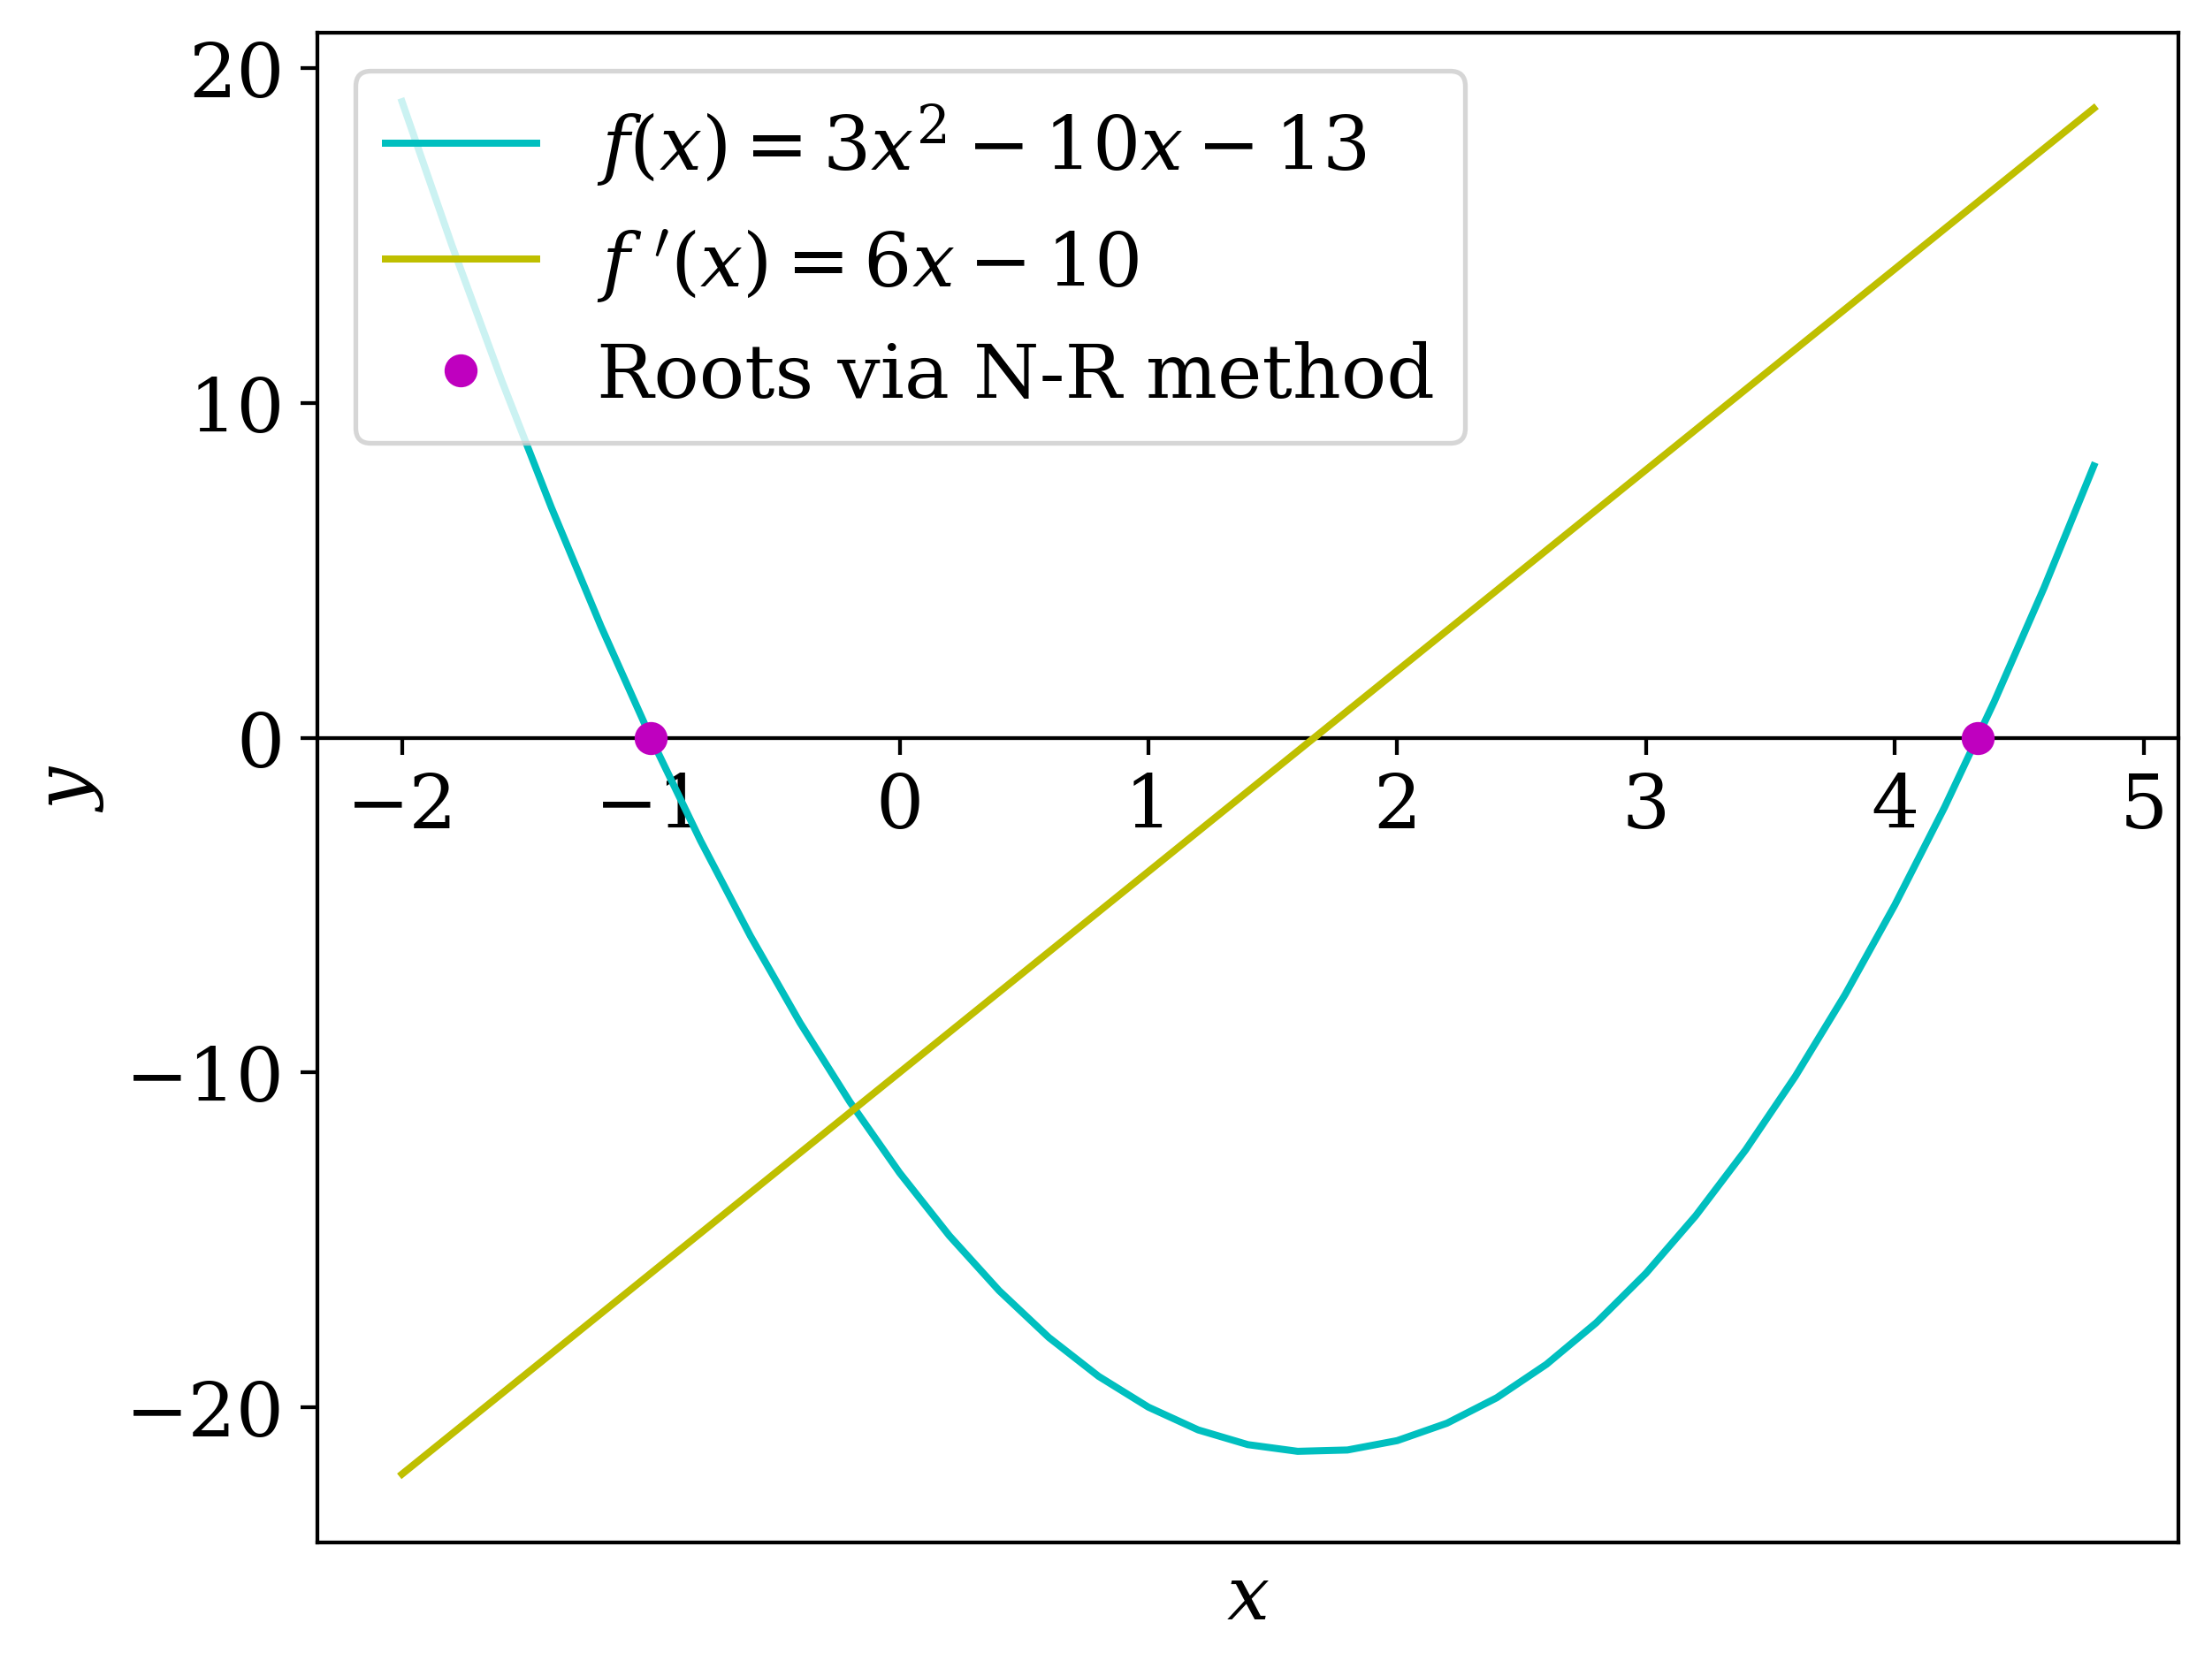

In [4]:
"""Derivative of parabola

f'(x) = 6 * x - 10
"""
def parabola_prime(x):
  return 6 * x -10


"""Find root x of function via Newton-Raphson method

Optionally return number of steps it took to find the root
"""
def newton_roots(x, tol=0.0001, steps=False):
  nsteps = 0

  while(abs(parabola(x))>tol):
    x = x - parabola(x) / parabola_prime(x)
    nsteps += 1

  return (x, nsteps) if steps else x


x1 = newton_roots(1)
x2 = newton_roots(3)

y1 = parabola(x1)
y2 = parabola(x2)

print(f'x1={x1:.6}\n%error={abs(x1-true_x1)*100/true_x1:.6}\nf(x1)={y1:.6}\n')
print(f'x2={x2:.6}\n%error={abs(x2-true_x2)*100/true_x2:.6}\nf(x2)={y2:.6}')

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(x, y, label='$f(x) = 3x^2-10x-13$', color='c')
ax.plot(x, parabola_prime(x), label='$f\ \'(x) = 6x-10$', color='y')
ax.plot((x1, x2), (y1, y2), 'mo', label='Roots via N-R method')

ax.legend()
ax.set_xticks([])
plt.xlabel('$x$')
plt.ylabel('$y$')

ax.secondary_xaxis(0, transform=ax.transData)

plt.savefig('nr_parabola.png', bbox_inches='tight')
plt.show()

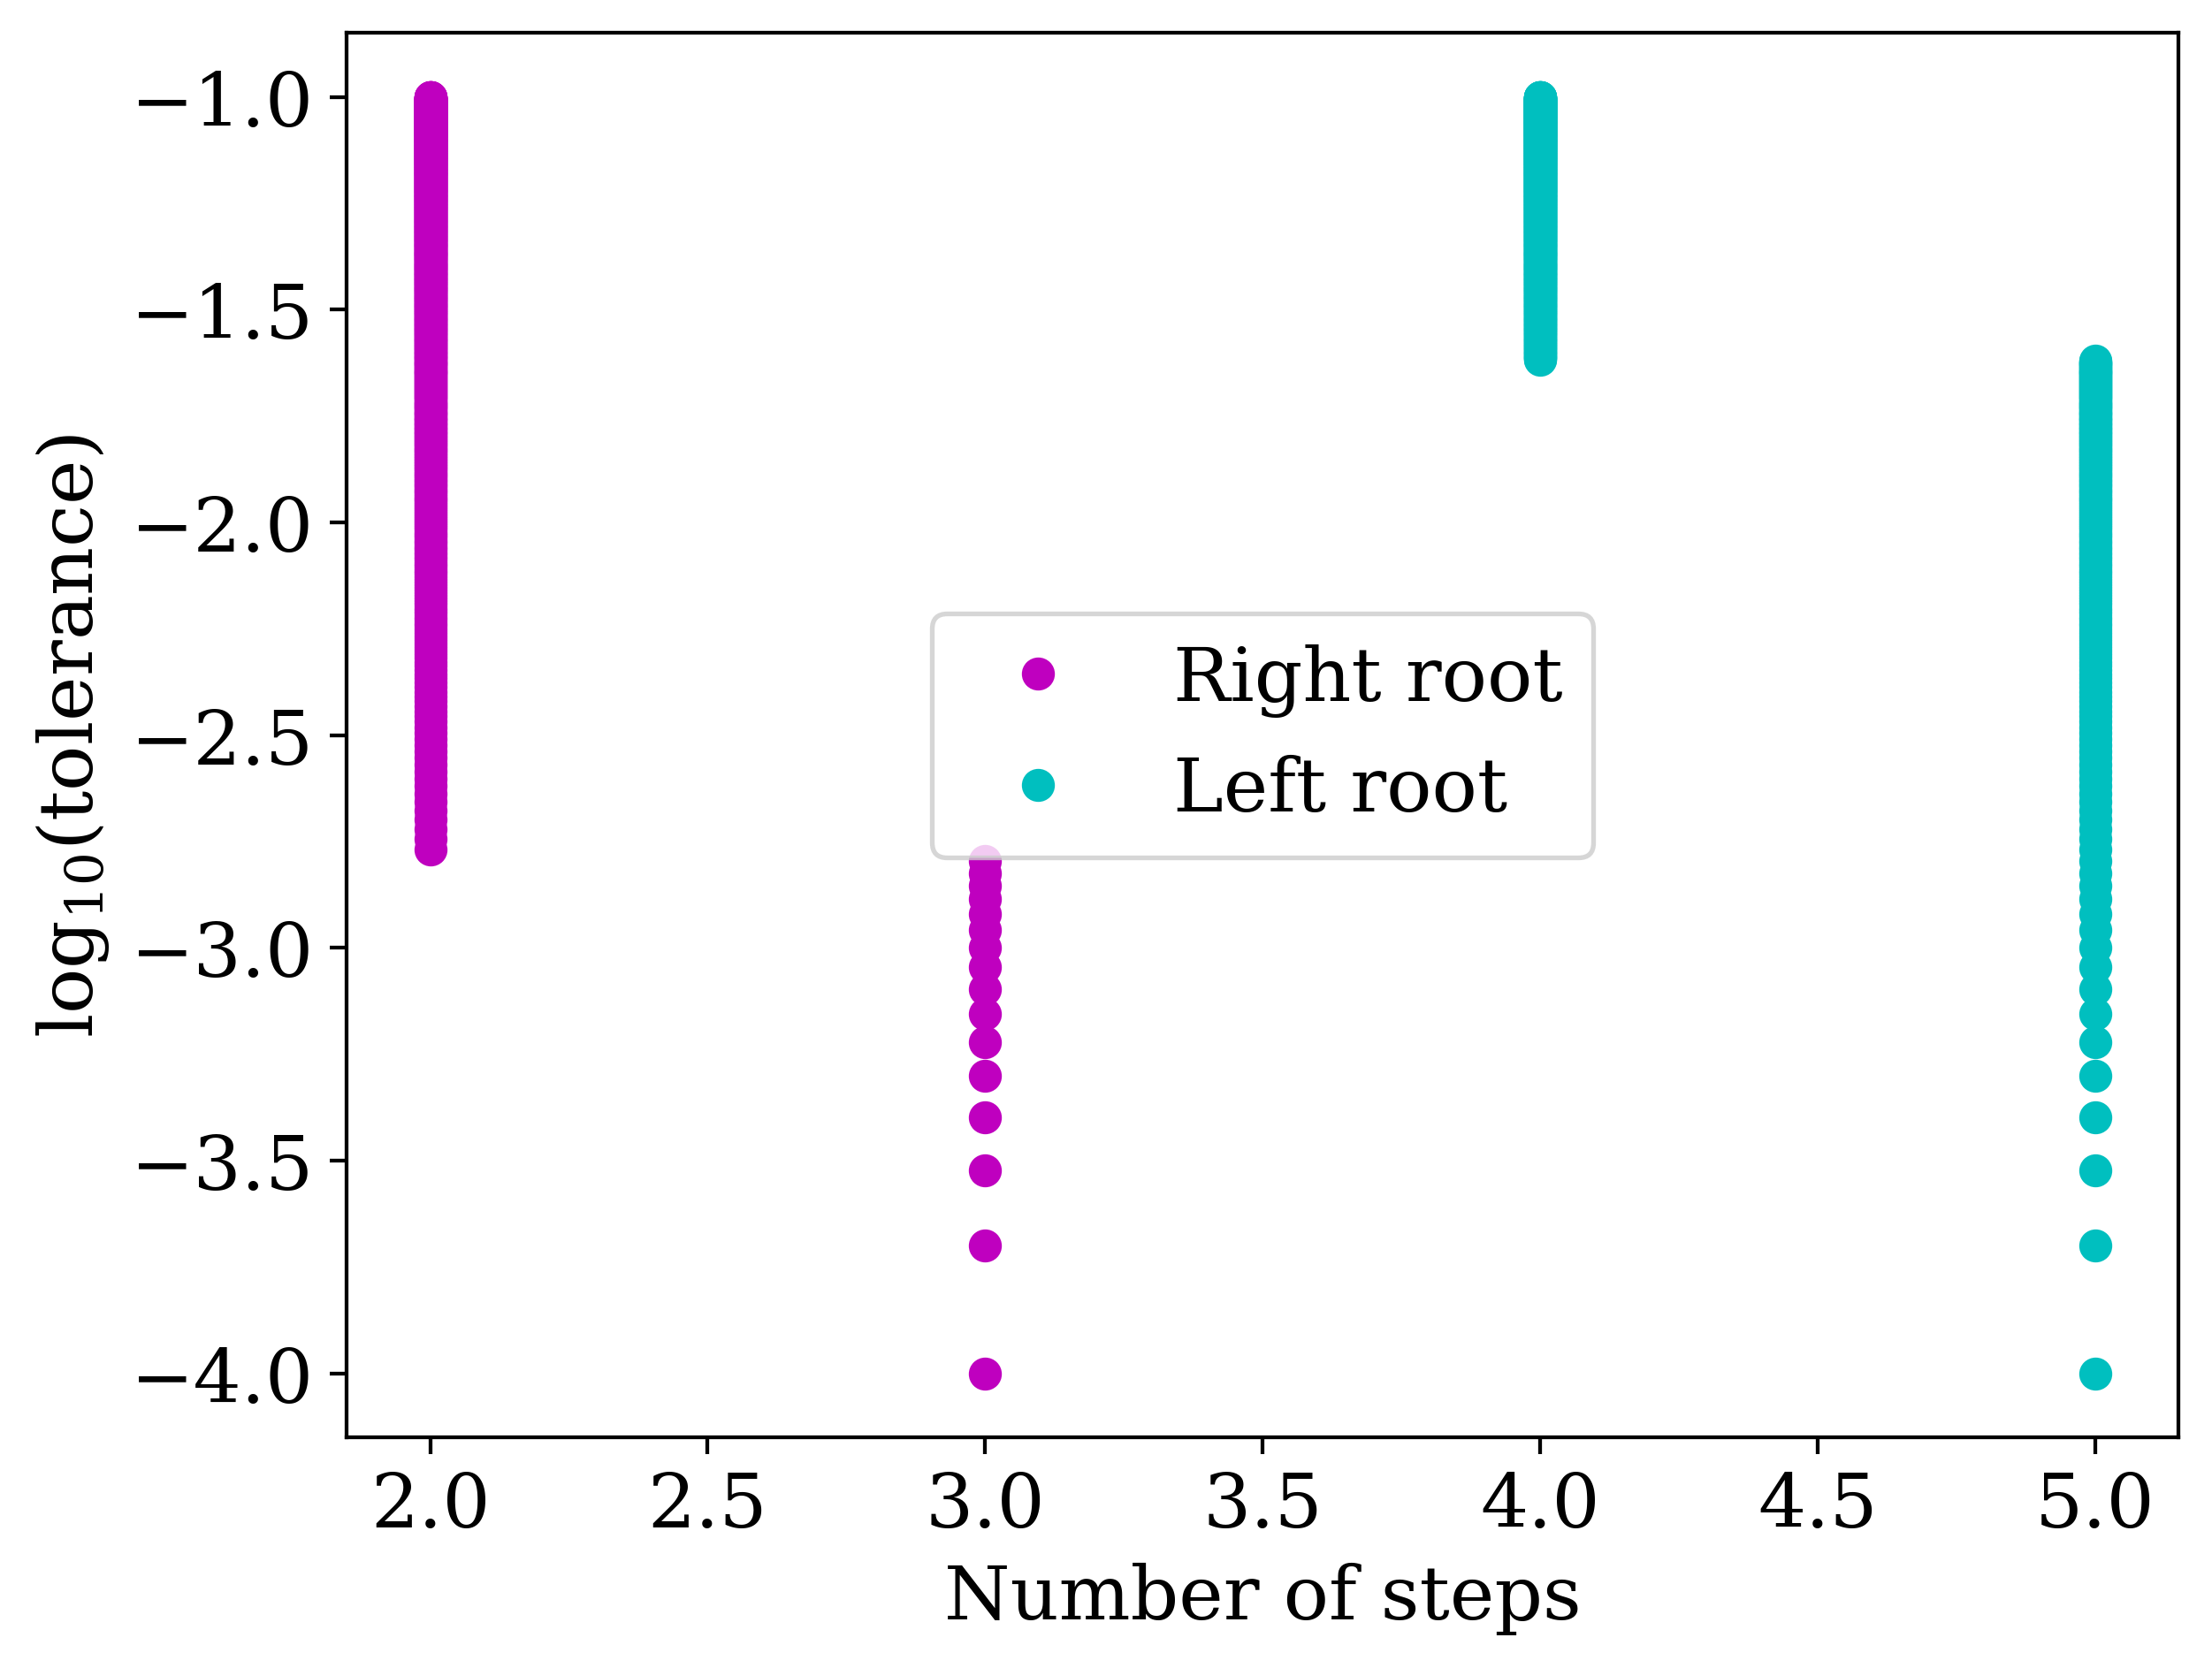

In [5]:
"""Get both roots via N-R method
"""
def find_roots(tol):
  _, nl = newton_roots(1, tol, True)
  _, nr = newton_roots(4, tol, True)
  return nr, nl

nsr, nsl = zip(*[find_roots(tol) for tol in tols])
tols_log10 = np.log10(tols)

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(nsr, tols_log10, 'mo', label='Right root')
ax.plot(nsl, tols_log10, 'co', label='Left root')
ax.legend()

plt.xlabel('Number of steps')
plt.ylabel('log$_{10}$(tolerance)')

plt.savefig('nr_steps.png', bbox_inches='tight')
plt.show()

# Exercise 3

x_min=0.236054
V(x_min)=-5.24749



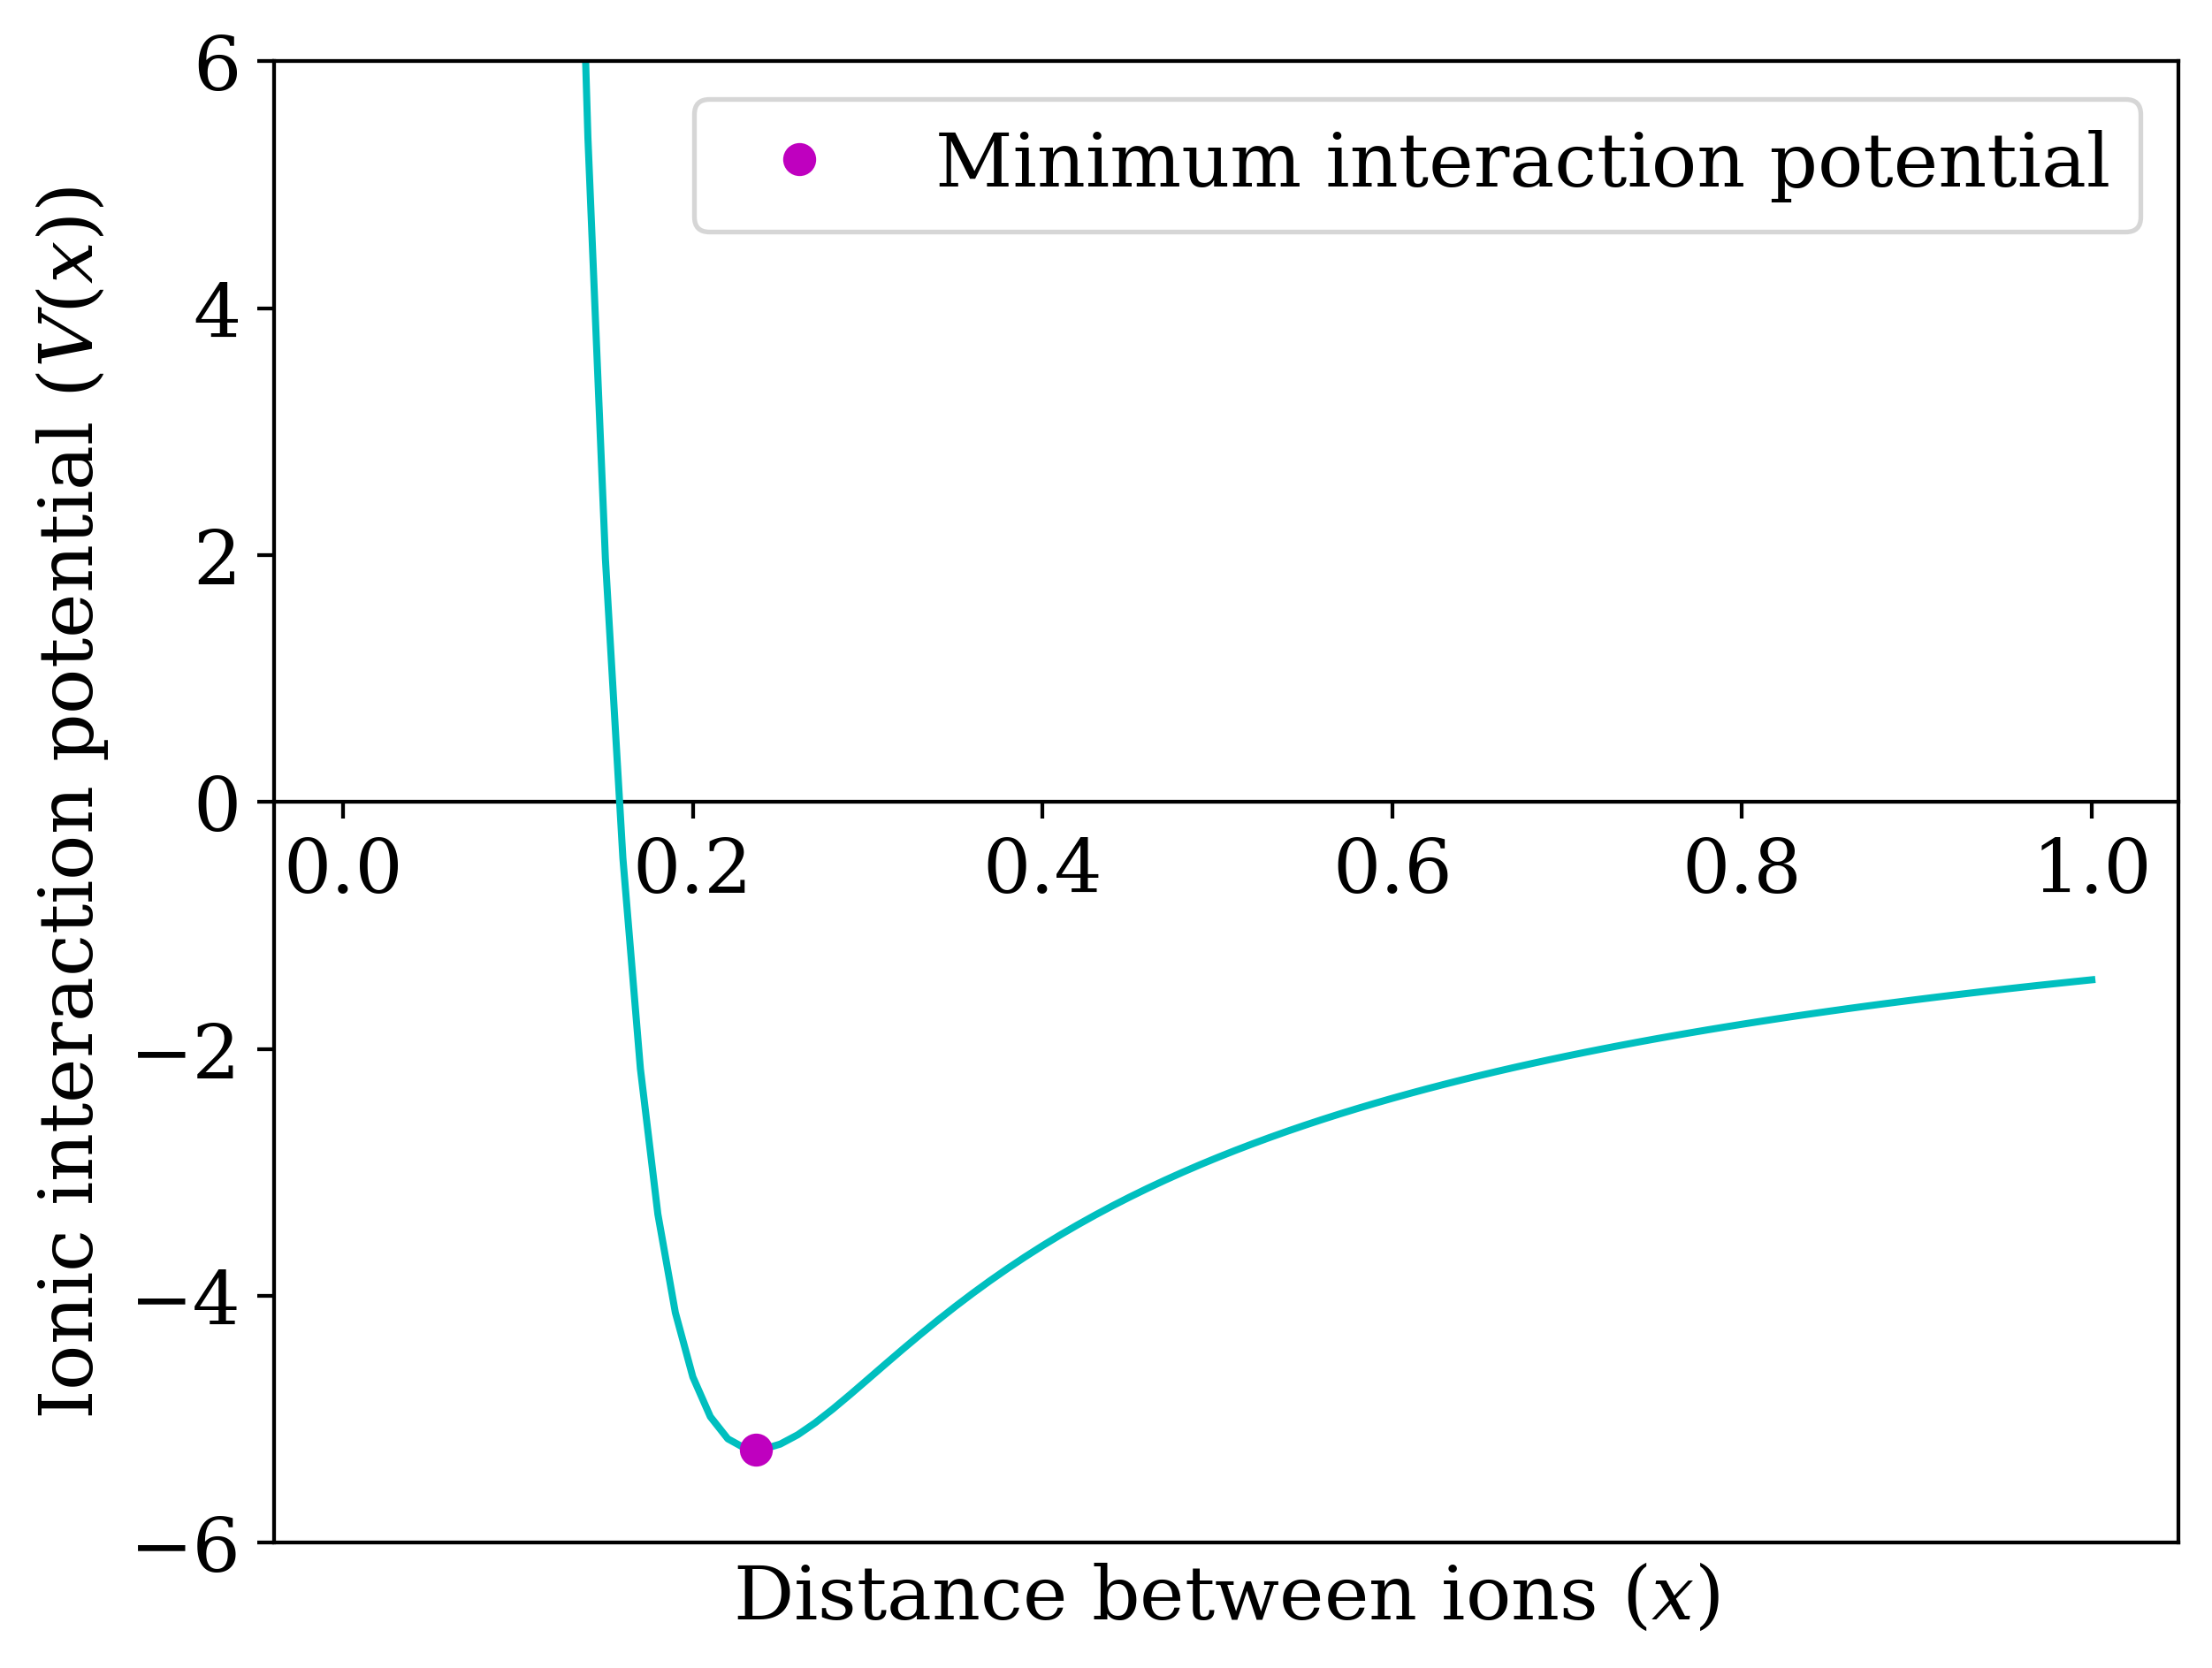

In [6]:
epi = 1.44
A = 1090
p = 0.033


"""Ionic potential energy function V(x)
"""
def V(x):
  return A * np.exp(- x / p) - epi / x


"""First derivative of V(x)
"""
def V_p(x):
  return epi / x**2 - A * np.exp(-x / p) / p


"""Force between ions
"""
def F(x):
  return -V_p(x)


"""Second derivative of V(x)
"""
def V_pp(x):
  return A * np.exp(-x / p) / p**2 - 2 * epi / x**3


"""Newton-Raphson method to find minimum of V(x)
"""
def newton_min(x, tol=0.0001):

  while(abs(V_p(x))>tol):
    x = x - V_p(x) / V_pp(x)

  return x


x = np.linspace(0.01, 1., num=100)

x_min = newton_min(0.2)
V_min = V(x_min)

print(f'x_min={x_min:.6}\nV(x_min)={V_min:.6}\n')

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(x, V(x), color='c')
ax.plot(x_min, V_min, 'mo', label='Minimum interaction potential')
plt.ylim(-6, 6)

ax.set_xticks([])
plt.xlabel('Distance between ions ($x$)')
plt.ylabel('Ionic interaction potential ($V(x)$)')
secax = ax.secondary_xaxis(0, transform=ax.transData)
plt.legend()

plt.savefig('potential.png', bbox_inches='tight')
plt.show()

x_min=0.236054
F(x_min)=7.42109e-09



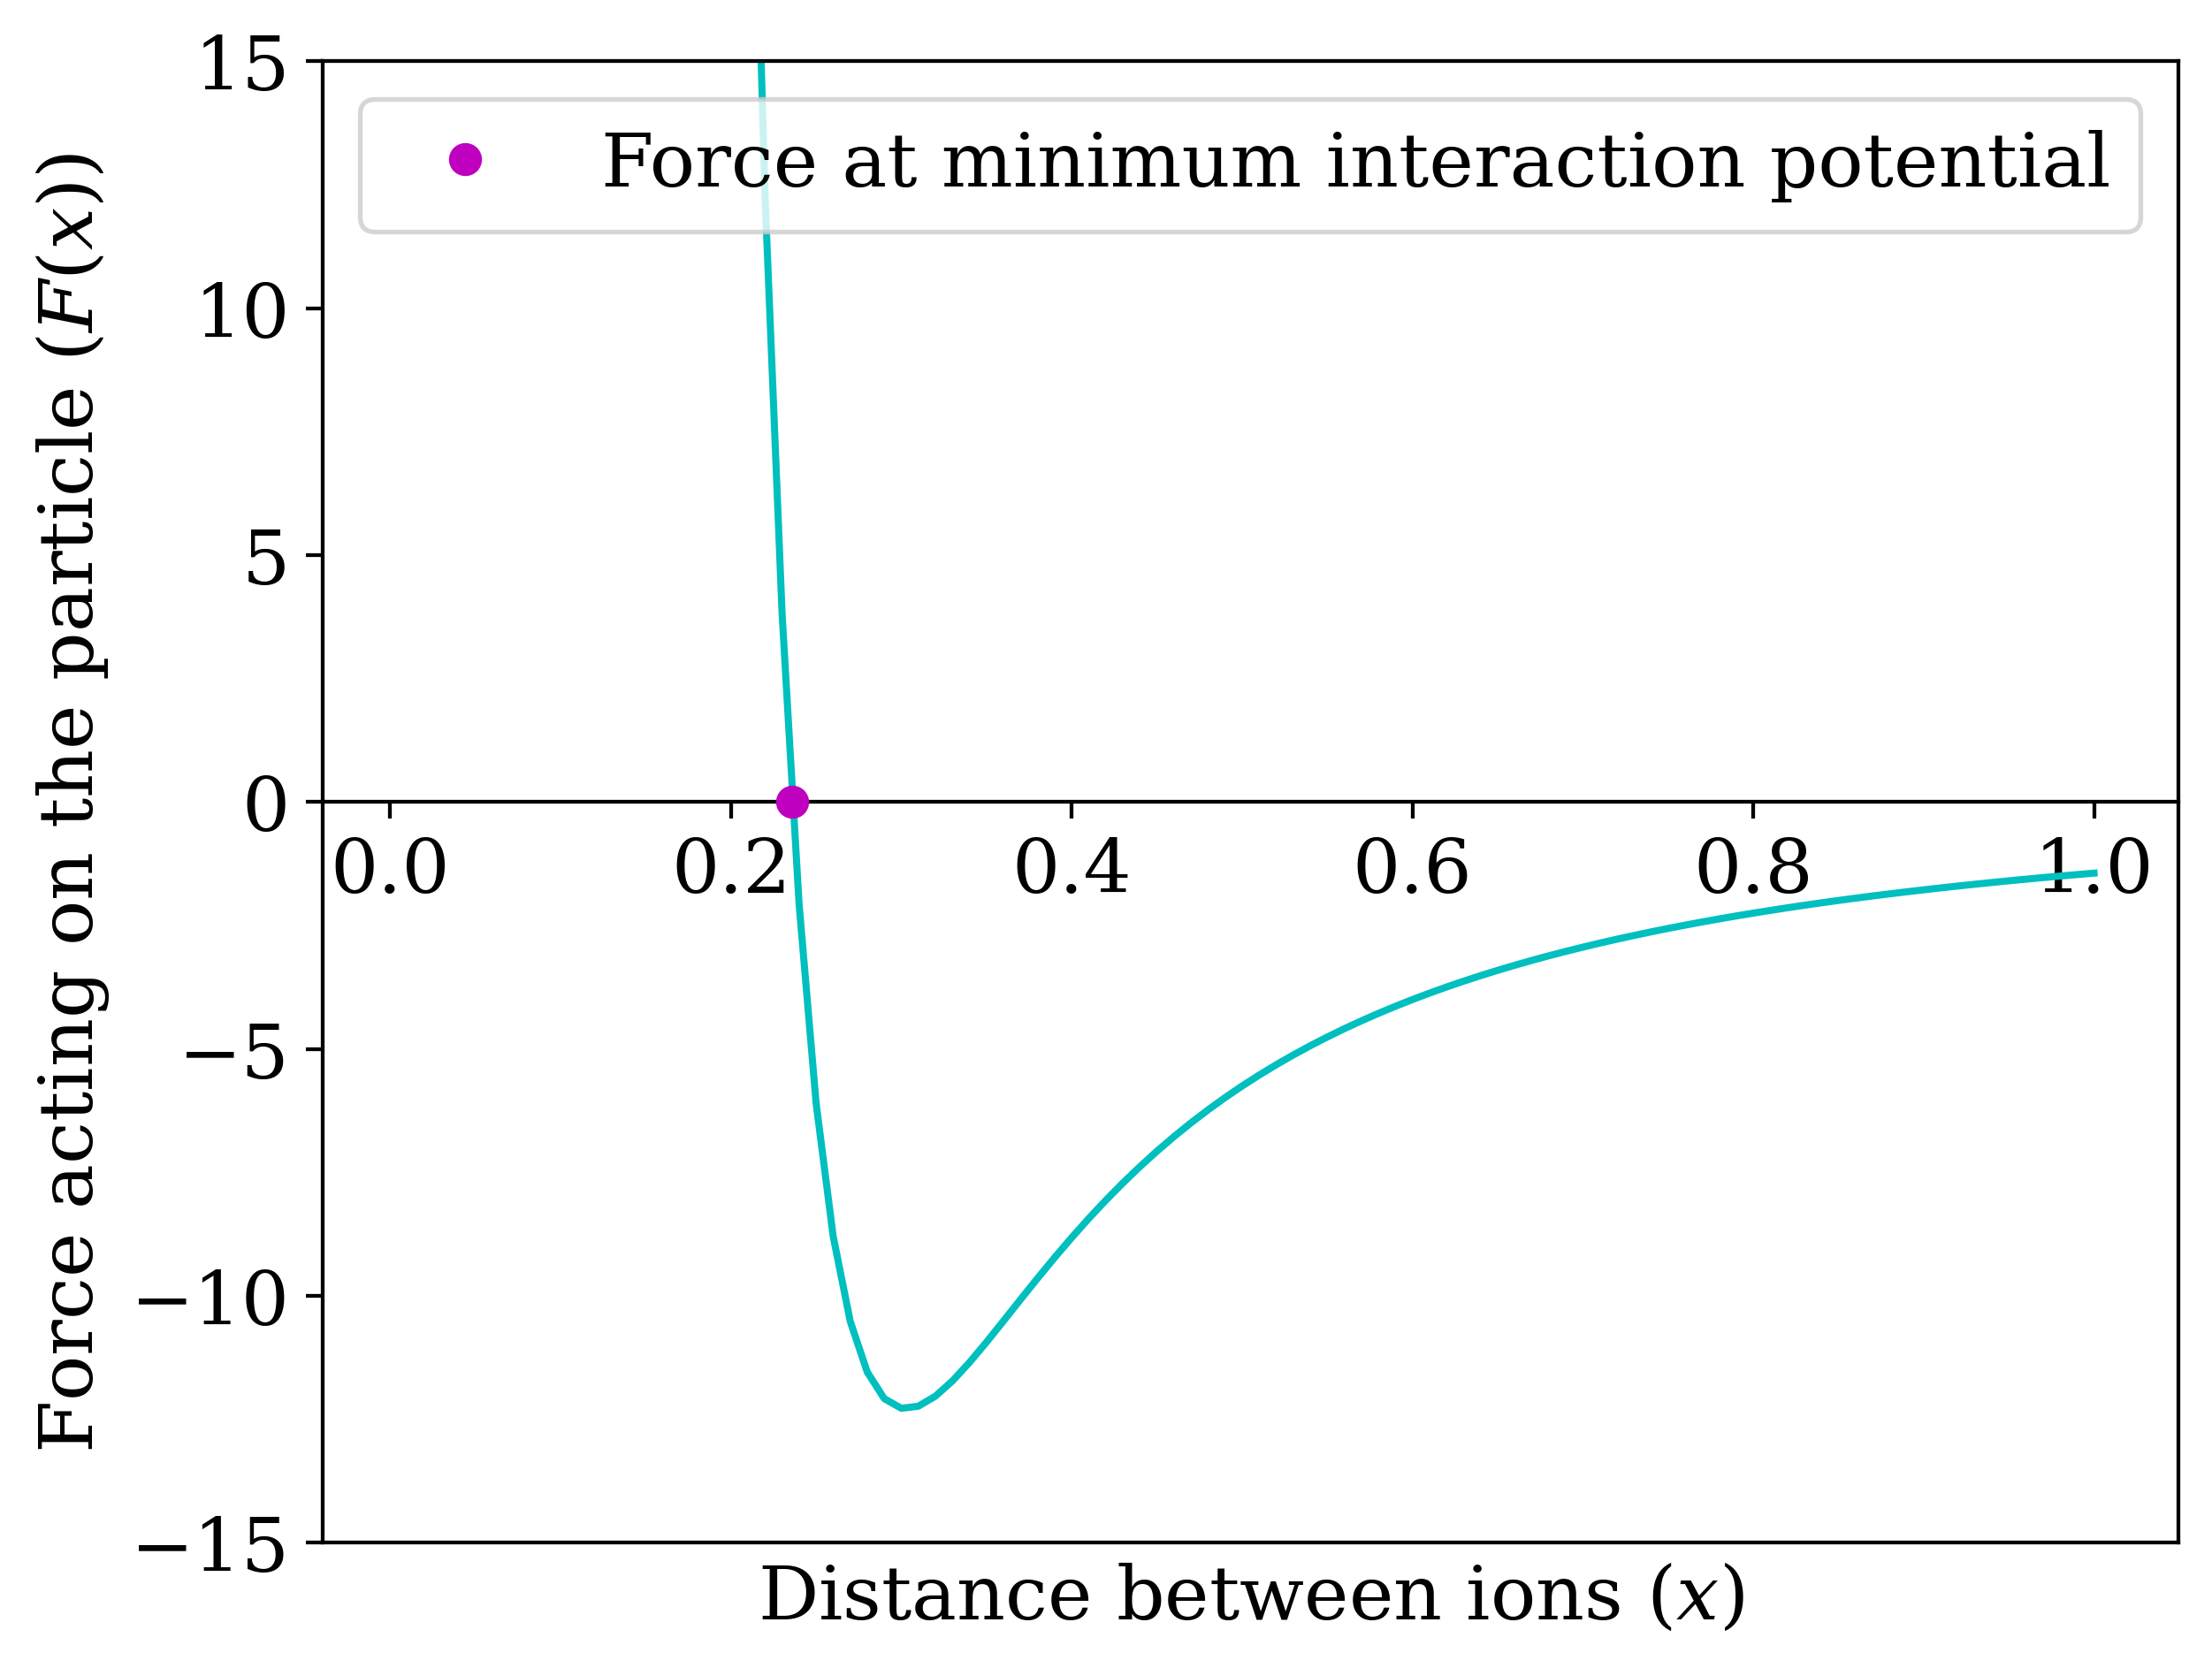

In [7]:
F_min = F(x_min)

print(f'x_min={x_min:.6}\nF(x_min)={F_min:.6}\n')

fig, ax = plt.subplots(constrained_layout=True, dpi=384)
ax.plot(x, F(x), color='c')
ax.plot(x_min, F_min, 'mo', label='Force at minimum interaction potential')
plt.ylim(-15, 15)

ax.set_xticks([])
plt.xlabel('Distance between ions ($x$)')
plt.ylabel('Force acting on the particle ($F(x)$)')
secax = ax.secondary_xaxis(0, transform=ax.transData)
plt.legend()

plt.savefig('force_zoomed.png', bbox_inches='tight')
plt.show()